<a href="https://colab.research.google.com/github/ricvazquez/ColabFiles/blob/main/Ricardo_Vazquez_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Ricardo Vazquez Macias  

**Matrícula:** 273509

**Fecha:** ______________

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [97]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | El cliente y sus caracteristicas |
| ¿Qué se predice? | Si el cliente contratara el deposito |
| ¿Qué tipo de problema es? | Aprendizaje supervisado |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | SE hara con la columna 'y'|
| ¿Qué columnas no deberían usarse como características y por qué? | Las columnas macro, ya que no son caracteristicas de la observacion, sino macroeconomicas |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Escribe tu respuesta aquí, antes de ejecutar la celda de código.
Al ser un dataset grande, creo que no mas de 40% haya contratado el servicio

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Regularmente en datasets tan grandes y al parecer crudos, siempre suelen haber faltantes, por errores humanos, o falta de informacion al momento de llenarlo

In [98]:
df.head(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [99]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

### Dimensiones del conjunto
print("Filas",df.shape[0])
print("Columnas",df.shape[1])
print("##################################")
## Tipo de dato por columna
print(df.info())
print("##################################")
## Numero de valores unicos por columna
unicos = df.nunique().sort_values(ascending = True)
print(unicos)

Filas 41188
Columnas 21
##################################
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  4

In [100]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

## Sacamos los supuestos Nan
print("Supuestos nulos:",df.isna().sum())
print("##################################")
## Hacemos un for para recorrer las columnas categoricas y buscamos la palabra uknown
print("Porcentajes de unknown")
for n in categoricas:
    uk = df[n].str.contains("unknown")
    if(uk.sum()>0):
      print("Columna:",n,"Cantidad:",uk.sum(),"\nPorcentaje:",uk.sum()/df.shape[0]*100)
      print("##################################")

Supuestos nulos: age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64
##################################
Porcentajes de unknown
Columna: job Cantidad: 330 
Porcentaje: 0.8012042342429834
##################################
Columna: marital Cantidad: 80 
Porcentaje: 0.1942313295134505
##################################
Columna: education Cantidad: 1731 
Porcentaje: 4.202680392347285
##################################
Columna: default Cantidad: 8597 
Porcentaje: 20.87258424783918
##################################
Columna: housing Cantidad: 990 
Porcentaje: 2.40361270272895
##################################
Columna

In [101]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
## Filas unicas
print("Filas Unicas:",df.nunique().sum().sum())

Filas Unicas: 2143


In [102]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

## Revisamos cuantos 999 hay en pdays
pday = df["pdays"] == 999
print("Cantidad en pdays:",pday.sum(),"\nPorcentaje:",pday.sum()/df.shape[0]*100)
print("##################################")

## Hacemos la tabla cuando previous vale cero
prev = pd.crosstab(df["poutcome"],df["previous"] == 0)
print(prev)
print("##################################")
## ahora cuando pdays vale 999
pday = pd.crosstab(df["poutcome"],df["pdays"] == 999)
print(pday)

Cantidad en pdays: 39673 
Porcentaje: 96.32174419733903
##################################
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0
##################################
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [103]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.

## Sacamos el maximo y el minimo de las edades
edadmin = df["age"].min()
edadmax = df["age"].max()
print("Edad minima:",edadmin,"\nEdad maxima:",edadmax, "\nRango:", edadmax-edadmin)
print("##############################")
## Sacamos las llamadas que tengan 0
llams = df["duration"] == 0
print("llamadas con duracion 0:",llams.sum(),"\nPorcentaje:",round(llams.sum()/df.shape[0],5)*100)
print("############################")
## Sacamos el maximo y minimo de campaing
campmin = df["campaign"].min()
campmax = df["campaign"].max()
print("Campaign minimo:",campmin,"\nCampaign maximo:",campmax)
print("############################")
## Sacamos el previous negativo
prev = df["previous"] < 0
print("Filas con previous negativo:",prev.sum())

Edad minima: 17 
Edad maxima: 98 
Rango: 81
##############################
llamadas con duracion 0: 4 
Porcentaje: 0.01
############################
Campaign minimo: 1 
Campaign maximo: 56
############################
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

Pudiera parecer que hay algunos registros con errores de captura, ya que una llamada estaria complicado que dure 0

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

Considerando que son poquito mas del 20%, lo mejor seria tratarla como una categoria mas, ya que si la inclinamos a si o no causaria un sesgo muy grande y si eliminamos las filas, perderiamos el 20% del dataset

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Si, con la funcion utilizada, y especificando la variable statify en la columna que queremos, nos aseguramos que las proporciones se mantengan despues de la separacion

In [104]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.

## Creamos la variable entrenamiento
entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)
print('Tamaño del entrenamiento:',entrenamiento.shape[0])
print('Tamaño de la prueba:',prueba.shape[0])
print("########################")
print("Porcentajes de yes, no del entrenamiento")
print(entrenamiento["y"].value_counts(normalize=True)*100)
print("########################")
print("Porcentajes de yes, no de la prueba")
print(prueba["y"].value_counts(normalize=True)*100)

ent = entrenamiento.copy()
ent["suscribe"] = (ent["y"] == "yes").astype(int)
ent.head(5)

Tamaño del entrenamiento: 32950
Tamaño de la prueba: 8238
########################
Porcentajes de yes, no del entrenamiento
y
no     88.734446
yes    11.265554
Name: proportion, dtype: float64
########################
Porcentajes de yes, no de la prueba
y
no     88.73513
yes    11.26487
Name: proportion, dtype: float64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,suscribe
25611,49,blue-collar,married,basic.9y,unknown,no,no,cellular,nov,wed,227,4,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,no,0
26010,37,entrepreneur,married,university.degree,no,no,no,telephone,nov,wed,202,2,999,1,failure,-0.1,93.200,-42.0,4.120,5195.8,no,0
40194,78,retired,married,basic.4y,no,no,no,cellular,jul,mon,1148,1,999,0,nonexistent,-1.7,94.215,-40.3,0.870,4991.6,yes,1
297,36,admin.,married,university.degree,no,yes,no,telephone,may,mon,120,2,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0
36344,59,retired,divorced,university.degree,no,no,no,cellular,jun,tue,368,2,999,0,nonexistent,-2.9,92.963,-40.8,1.262,5076.2,no,0


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [105]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

Si, gracias a la funcion y la variable stratify, podemos ver como se mantuvieron las proporciones de yes,no en entrenamiento y prueba

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Considerando que no, es el 88% del dataset, pues tendria esa misma exactitud

Porcentajes de yes, no en ent
     Cantidad  Porcentaje
y                        
no      29238   88.734446
yes      3712   11.265554
########################
Razon entre clases
7.88
########################
Exactitud de responder siempre no
89.0
########################
Grafica de barras


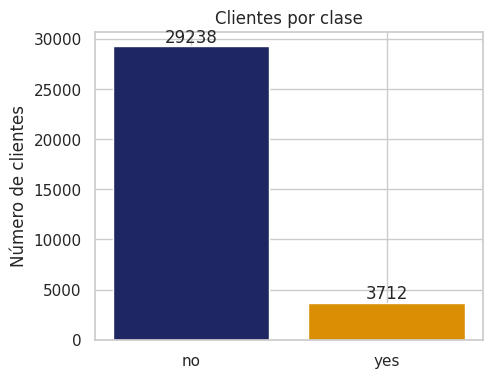

In [106]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.

## Sacamos los datos que nos ayudaran en as graficas
grap = ent["y"].value_counts()
por = ent["y"].value_counts(normalize=True)*100
## Hacemos un mini dataframe para el porcentaje y numeros
num = pd.DataFrame({"Cantidad":grap,"Porcentaje":por})
print("Porcentajes de yes, no en ent")
print(num)
print("########################")
print("Razon entre clases")
print(round(ent["y"].value_counts(normalize=True).max()/ent["y"].value_counts(normalize=True).min(),2))
print("########################")
print("Exactitud de responder siempre no")
print(round(ent["y"].value_counts(normalize=True).max(),2)*100)
print("########################")
print("Grafica de barras")

## Hacemos la grafica de los yes y no
fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(grap.index, grap.values, color=grap.index.map(COLORES_CLASE))
ax.bar_label(barras)
ax.set_title("Clientes por clase")
ax.set_ylabel("Número de clientes")
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

En las predicciones de A sin conocer mucho los datos podiamos decir que la probabilidad de que no contrataran el plan, era mayor. Ahora con los datos ya pudieramos peerfilar un porcentaje basandonos en el historico de los mismos

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Yo creo que la que mas va a variar es la edad(age), ya que depende mucho de tu edad si quieres contratar algo asi o no. Y el previous, no es lo mismo que te lo ofrezcan 1 vez a 6 veces, deberia de ser mas comun los numeros altos en el yes

      age  duration  campaign  pdays  previous  emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed
y                                                                                                                  
no   38.0     164.0       2.0  999.0       0.0           1.1          93.918          -41.8      4.857       5195.8
yes  37.0     448.0       2.0  999.0       0.0          -1.8          93.200          -40.4      1.266       5099.1
########################
Diagramas de caja


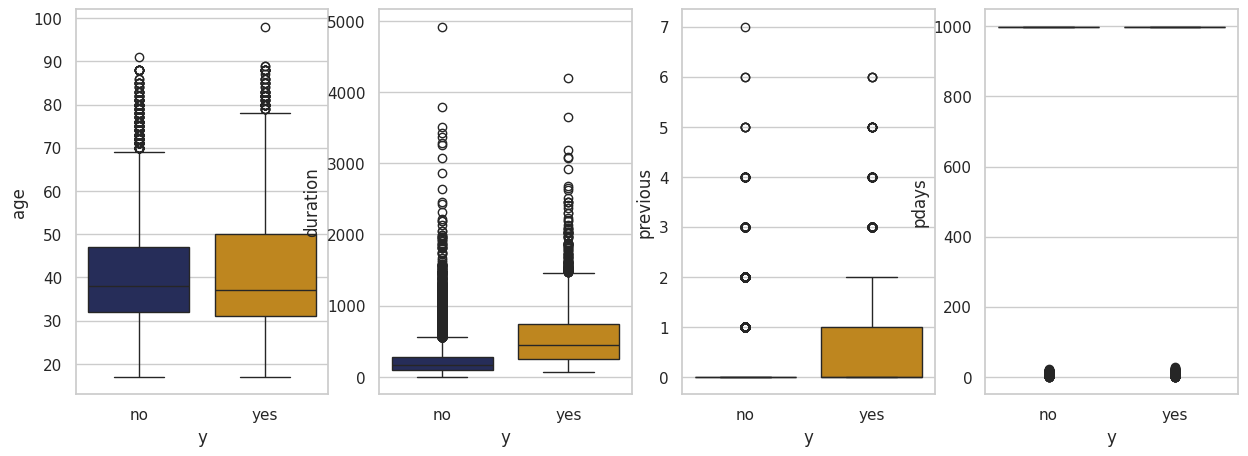

In [107]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.

## Ignoramos las alarmas
import warnings
warnings.filterwarnings("ignore")
## Sacamos las medias y agrupos con la columna y
nums = ent.groupby("y")[numericas].median()
print(nums)
print("########################")
## Hacemos las graficas de los dos que crei que iban a ser con mas diferencia, y del qu en verdad lo fue
print("Diagramas de caja")
fig, axs = plt.subplots(1, 4, figsize=(15, 5))
sns.boxplot(data=ent, x="y", y="age", palette = COLORES_CLASE, ax=axs[0])
sns.boxplot(data=ent, x="y", y="duration", palette = COLORES_CLASE, ax=axs[1])
sns.boxplot(data=ent, x="y", y="previous", palette = COLORES_CLASE, ax=axs[2])
## Pdays no la tenia contemplada, pero no entendia sus limites en la parte abajo, por eso la agregue
sns.boxplot(data=ent, x="y", y="pdays", palette = COLORES_CLASE, ax=axs[3])
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

La edad si se ve diferencia, pero los outliers en el no, hacen parecer que los promedios entre ambos estan muy justos, y en el previous

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Por lo visto, en la grafica naterior, previous engloba muchos datos en cero, lo que pudiera hacer que los qauntiles se vean sesgados, pudiendo parecer que tenga muchos datos fuera de limites, aunque esos limites sean muy cercanos a cero

In [108]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ran = q3 - q1
lim_sup = q3 + 1.5*ran
lim_inf = q1 - 1.5*ran
print("Limite superior")
print(lim_sup)
print("########################")
print("Limite inferior")
print(lim_inf)
print("##########################")
print("Fuera de rango")
print(((ent[numericas]<lim_inf)|(ent[numericas] > lim_sup)).sum())

Limite superior
age                 69.5000
duration           643.0000
campaign             6.0000
pdays              999.0000
previous             0.0000
emp.var.rate         6.2000
cons.price.idx      95.3725
cons.conf.idx      -26.9500
euribor3m           10.3865
nr.employed       5421.6000
dtype: float64
########################
Limite inferior
age                  9.5000
duration          -221.0000
campaign            -2.0000
pdays              999.0000
previous             0.0000
emp.var.rate        -6.6000
cons.price.idx      91.6965
cons.conf.idx      -52.1500
euribor3m           -4.0815
nr.employed       4905.6000
dtype: float64
##########################
Fuera de rango
age                368
duration          2366
campaign          1916
pdays             1226
previous          4534
emp.var.rate         0
cons.price.idx       0
cons.conf.idx      359
euribor3m            0
nr.employed          0
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.
 De age pudiera parecer normal que hayan registros atipicos, y no se eliminarian, duration habria que ver si las llamadas de mas de 6 hrs son reales o fueron errores de captura. Los registros de campaign tambien pudieran verse reales. Pdays al tener un limite inferior de 999 deja  a los demas datos como 'atipicos'cuando en realidad no lo son. Y previous al tener mucho cero tambien hace parecer que los demas datos son atipicos, cuando tampoco lo son.
 No borraria los datos atipicos en esta ocasion, los mantendria para mantener la integridad del dataset


### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

En este caso que son rangos de valores aparantemente pequeños, posiblemente la logaritmica pueda dar un mejor resultado

          Original   Raiz C   Logaritmo
age       0.760819  0.426057   0.132406
duration  3.326612  1.203716  -0.430172
campaign  4.742537  2.162976   1.350996
########################


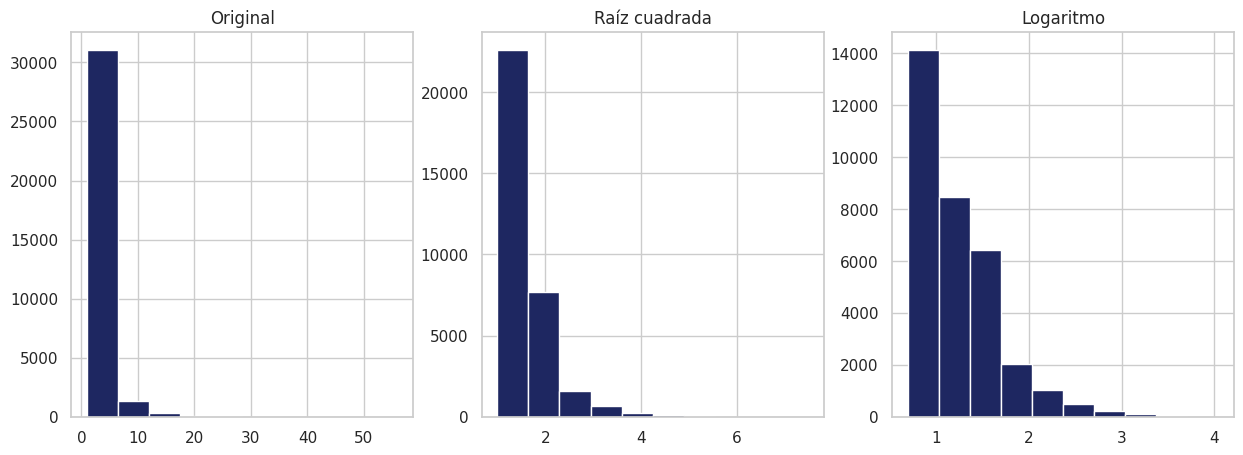

In [109]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

## Hacemos un dataset con la asimetria original, las dos transformaciones como se hizo en el ejemplo compartido
var = ['age', 'duration', 'campaign']
comp = pd.DataFrame({
      "Original":ent[var].skew(),
      "Raiz C ": ent[var].apply(np.sqrt).skew(),
      "Logaritmo": ent[var].apply(np.log1p).skew()
    })
print(comp)
print("########################")
### Graficamos solo el de campaign
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].hist(ent['campaign'].dropna(), color=AZUL, edgecolor="white")
axs[0].set_title("Original")
axs[1].hist(np.sqrt(ent['campaign']).dropna(), color=AZUL, edgecolor="white")
axs[1].set_title("Raíz cuadrada")
axs[2].hist(np.log1p(ent['campaign']).dropna(), color=AZUL, edgecolor="white")
axs[2].set_title("Logaritmo")
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

Como podemos ver en as graficas, la logaritmica fue la que mejor resultado dio, siendo la que mas se acerca a cero para el caso de campaign
 en age tambien usaria la logaritmica.
 Y en duration la que mejor resultado dio fue la de la raiz cuadrada.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Creo que las que mas influiran seran la de education, job, loan, housing y default, ya que education, psoiblemente los yes se carguen mas de lado de las personas que tiene preparatoria o mas, igual con el de job, sean para ciertos tipos de trabajos. y las ultimas 3 al ser relacionadas con prestamos, posiblemente la gente que ya tenga 1 prestamo o 2, necesiten este tipo de servicio

In [110]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.
## Valores unicos
print("Valores unicos")
print(ent[categoricas].nunique().sort_values(ascending = False))
print("########################")
print("Tasa global de contratacion")
print(round(ent['suscribe'].mean()*100,2),'%')

Valores unicos
job            12
month          10
education       8
day_of_week     5
marital         4
default         3
loan            3
housing         3
poutcome        3
contact         2
dtype: int64
########################
Tasa global de contratacion
11.27 %


In [111]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

## Creamos el melt con la columna de suscribe
largo = ent[categoricas].astype(str).assign(cont = ent['suscribe']).melt(
    id_vars = 'cont',
    var_name = "Caracteristica",
    value_name = 'Categoria'
)
## Agrupamos
tasas = largo.groupby(["Caracteristica","Categoria"])['cont'].agg(clientes = 'count', tasa_y = 'mean')
tasas["tasa_y"] = (tasas["tasa_y"]*100).round(1)

## las 12 Con mayor tasa
print("12 con mayor tasa\n")
print(tasas.sort_values(by='tasa_y', ascending=False).head(12))
print("########################")
## las 8 con menor tasa
print("8 con menor tasa")
print(tasas.sort_values(by='tasa_y', ascending=True).head(8))
print("########################")
## las tablas de default, housing, loan y day_of_week
print("Default")
print(tasas.loc["default"])
print("########################")
print("Housing")
print(tasas.loc["housing"])
print("########################")
print("Loan")
print(tasas.loc["loan"])
print("########################")
print("Day_of_week")
print(tasas.loc["day_of_week"])

12 con mayor tasa

                           clientes  tasa_y
Caracteristica Categoria                   
poutcome       success         1105    64.9
month          dec              143    50.3
               mar              436    49.8
               sep              464    44.6
               oct              587    43.3
job            student          711    30.5
               retired         1366    25.5
month          apr             2085    20.5
education      illiterate        16    18.8
marital        unknown           65    16.9
education      unknown         1397    14.8
contact        cellular       20908    14.7
########################
8 con menor tasa
                            clientes  tasa_y
Caracteristica Categoria                    
default        yes                 3     0.0
               unknown          6940     5.2
contact        telephone       12042     5.3
month          may             11011     6.3
job            blue-collar      7441     6.9
educatio

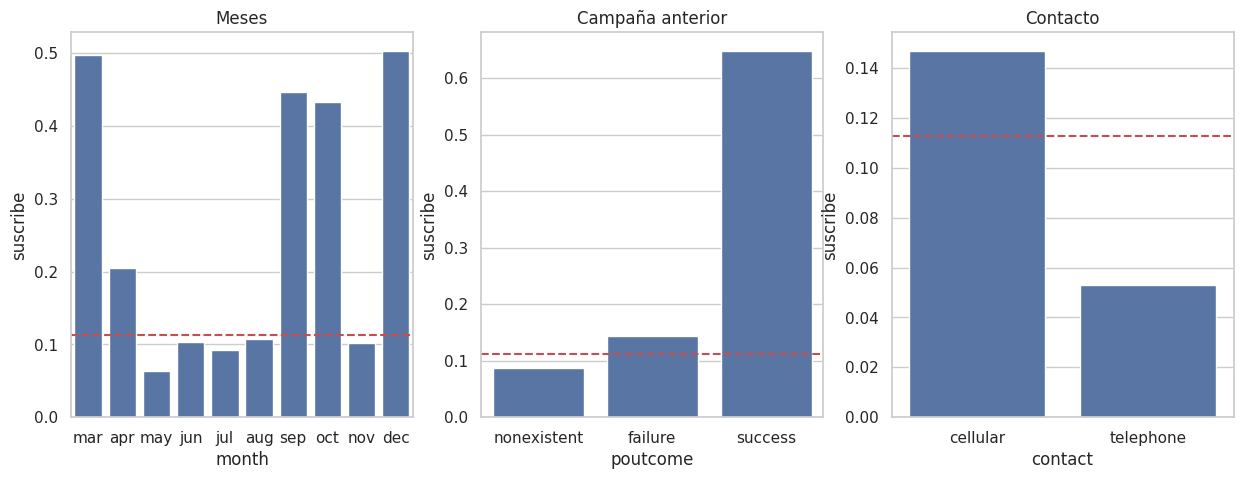

In [112]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.


## Hacemos la grafica como lo vimos en el ejemplo de telco
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
sns.barplot(data=ent, x="month", y="suscribe", order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], errorbar=None, ax=axs[0])
sns.barplot(data=ent, x="poutcome", y="suscribe", ax=axs[1], errorbar=None)
sns.barplot(data=ent, x="contact", y="suscribe", ax=axs[2], errorbar=None)
axs[0].axhline(y=ent['suscribe'].mean(), color='r', linestyle='--')
axs[1].axhline(y=ent['suscribe'].mean(), color='r', linestyle='--')
axs[2].axhline(y=ent['suscribe'].mean(), color='r', linestyle='--')
axs[0].set_title("Meses")
axs[1].set_title("Campaña anterior")
axs[2].set_title("Contacto")
plt.show()



**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

Por lo visto, si poutcome fue un exito, hay una probabilidad muy grande de que contrate el servicio, , y de ahi, en diciembre y en marzo son las siguientes detonantes, y que es mejor contactar a la gente por celular que por telefono

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

que uknown sea distinta a la de no, nos dice que no hubieramos podido agruparla con no, y tampoco con yes, que hicimos bien en no convertirla, ya que para donde sea que la hubieramos agregado, hubieramos sesgado el dataset
Con iliterate podemos decir que es un numero muy pequeño para sacar alguna relacion, considerando que solo fueron 6 clientes, asi que no se ve como una causalidad





## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Posiblemente la tasa de variacion de empleos y el numero de empleados en el mercado vayan muy de la mano

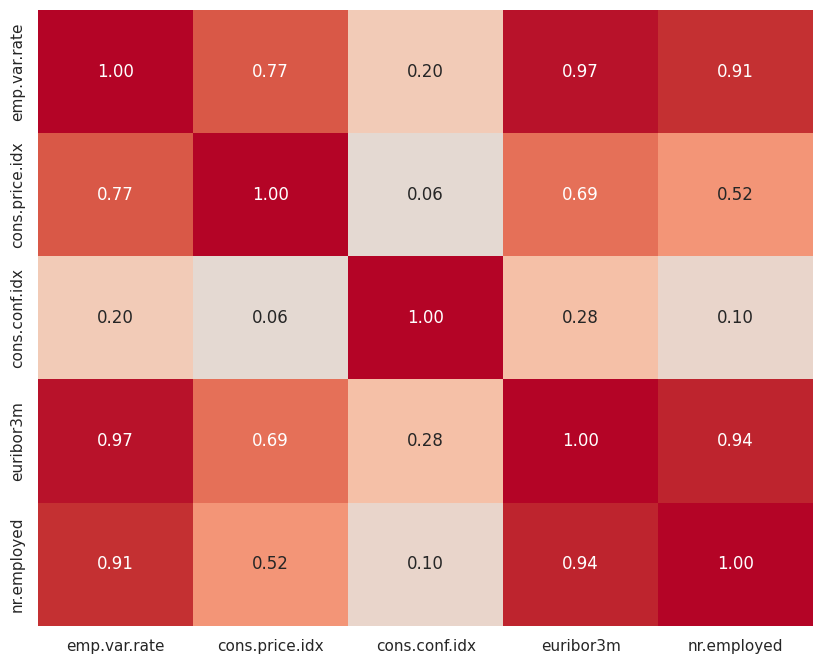

In [113]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

## Hacemos la matriz de correlacion
fig, axs = plt.subplots(figsize=(10, 8))
sns.heatmap(ent[macro].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, cbar=False, ax=axs)
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

Las mas relacionadas son la euribor3m tanto con numero de empleados, como con la tasa de variacion de empleos

Por lo que pude investigar la tasa de euribor es un indicador de los prestamos que se realizan entre bancos, practicamente pareciera que pudiera indicar una buena economia en el pais, con la cual se relaciona directamente con la tasa de variacion de empleos y el numero de empleados en el mercado

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [114]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.
print(ent.groupby("y")["duration"].describe())

       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

No, ya que es una variable que no se puede saber previa al evento, y no es realmente un causal del si, sino al reves, el si es causal de que dure mas la llamada.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

Es bueno siempre y cuando se asegure que la columna que se quiere predecir mantiene sus porcentajes de exito, ya que si no se hace de esa manera, al momento de que quieras usar el segundo como prueba, no te servira de nada ya que no sera una aproximacion real a los datos obtenidos

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
|Uknown en default no se puede ni eliminar ni renombrar para agruparlo con otra categoria |Se dejo como una categoria aparte |Default |
|Los meses mas bajos de la campaña fueron may, jun, jul, aug, nov promedio menor a la tasa (11%) |Deberia de dejar de hacerse esos meses |Month |
|pdays tiene un error de registro con 999 que representa el 96% de las filas |re convertir 999 a 0 |pdays |
|Duration no sirve para predecir en el dataset |Ignorar columna |  duration|
|Iliterate tiene muy pocos registros para se categoria tal vez seria  mejor ignorarla |Borrar del dataset |educatio |
|Uknown en marital tambien pudiera meter sesgo son muy pocas filas|Eliminar esas filas |marital |
|Job tiene demasiadas valores unicos, pudieran agruparse y no ser tan especificos |re agrupar las categorias de job y education | job|
|Education tambien pudiera agruparse en menos categorias, dejar solo un basic| minimizar education| Education

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

Con el conjunto de completo se hicieron
*   Definicion del problema
*   Descripcion de los datos y deteccion de calidad

Con el de entrenamiento se hicieron

*   División en entrenamiento y prueba
*   Valores atípicos
*   Asimetría y re-expresión
*   Exploración de las variables categóricas








**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

En toeria al habernos asegurado que la division del conjunto haya sido igual en los porcentajes de exito en y, las conclusiones solo hubieran sido sesgadas por el numero total de filas, pero los porcentajes deberian de ser los mismos, ya que no no fue una separacion al azar